# Atividade – Machine Learning
**Aluno:** Matheus · **Curso:** Sistemas de Informação – Univille

Roteiro da atividade:
1. **Definir uma base de dados**
2. **Definir que tipo de análise será feita**
3. **Implementar uma tarefa de Machine Learning**

## 1. Base de dados

**Breast Cancer Wisconsin (Diagnostic)**, do repositório UCI, que vem embutida no scikit-learn.

- **569 amostras**: cada uma é um exame de punção aspirativa (PAAF) de um nódulo mamário.
- **30 atributos numéricos** calculados a partir da imagem digitalizada dos núcleos celulares. São 10 características (raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal), cada uma em três versões: média, erro padrão e "pior" valor.
- **Alvo (target)**: diagnóstico **maligno** ou **benigno**.

Motivos da escolha: é uma base real, limpa (sem valores ausentes), de tamanho adequado para fins didáticos e com um problema de impacto prático claro.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, recall_score)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
dados = load_breast_cancer(as_frame=True)
df = dados.frame.copy()
# No dataset original, 0 = maligno e 1 = benigno. Invertemos para 1 = maligno (classe de interesse).
df["diagnostico"] = np.where(df["target"] == 0, 1, 0)
df = df.drop(columns="target")

print("Formato:", df.shape)
print("Valores ausentes:", df.isna().sum().sum())
df.head()

Formato: (569, 31)
Valores ausentes: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnostico
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


### Análise exploratória

diagnostico
Benigno    357
Maligno    212
Name: count, dtype: int64
diagnostico
Benigno    62.7 %
Maligno    37.3 %
Name: count, dtype: str


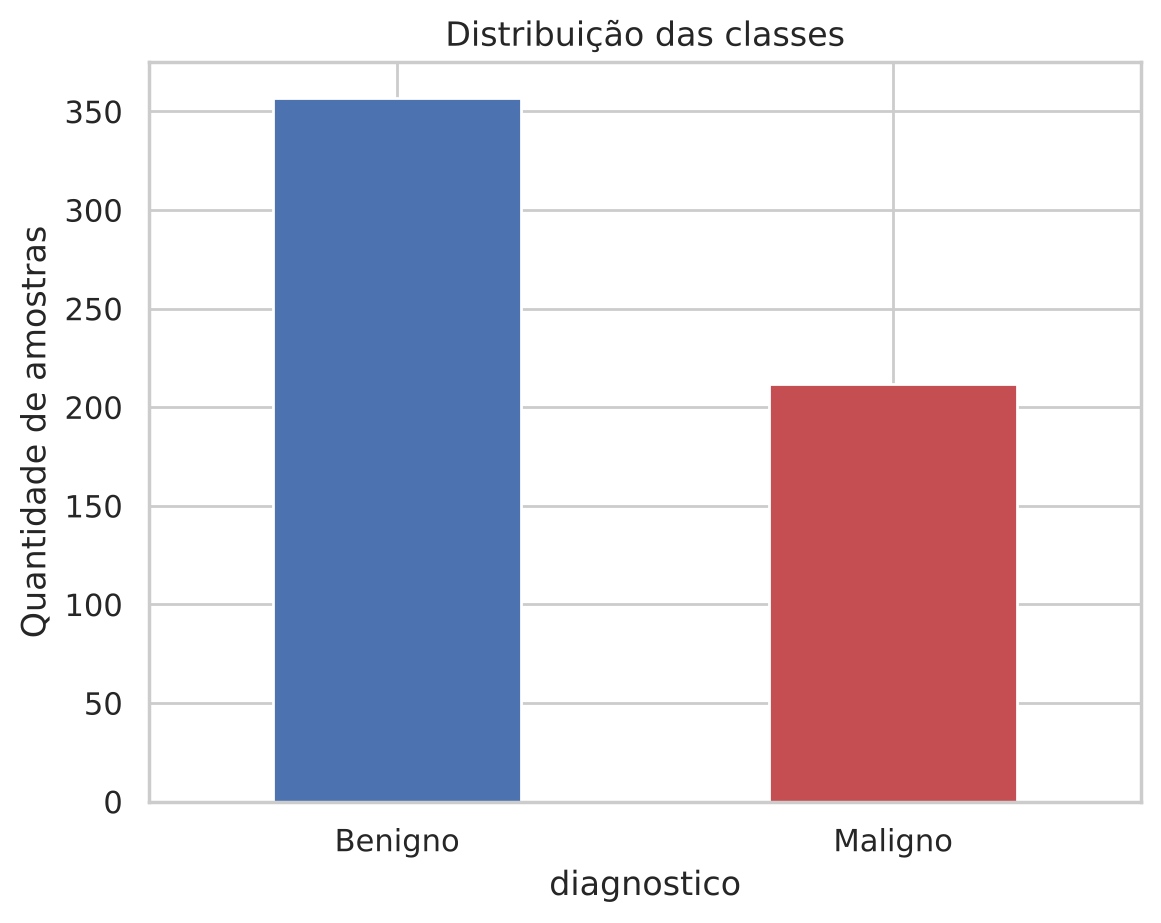

In [3]:
contagem = df["diagnostico"].map({1: "Maligno", 0: "Benigno"}).value_counts()
print(contagem)
print((contagem / len(df) * 100).round(1).astype(str) + " %")

ax = contagem.plot(kind="bar", color=["#4C72B0", "#C44E52"], rot=0)
ax.set_title("Distribuição das classes"); ax.set_ylabel("Quantidade de amostras")
plt.show()

As classes estão **levemente desbalanceadas** (~63% benigno / ~37% maligno). Por isso a divisão treino/teste e a validação cruzada serão **estratificadas**, e vamos olhar outras métricas além da acurácia.

In [4]:
df.describe().T[["mean", "std", "min", "max"]].head(10).round(2)

,mean,std,min,max
mean radius,14.13,3.52,6.98,28.11
mean texture,19.29,4.30,9.71,39.28
mean perimeter,91.97,24.30,43.79,188.50
mean area,654.89,351.91,143.50,2501.00
mean smoothness,0.10,0.01,0.05,0.16
mean compactness,0.10,0.05,0.02,0.35
mean concavity,0.09,0.08,0.00,0.43
mean concave points,0.05,0.04,0.00,0.20
mean symmetry,0.18,0.03,0.11,0.30
mean fractal dimension,0.06,0.01,0.05,0.10


Os atributos têm escalas muito diferentes (a *área* passa de 2.000, a *suavidade* fica perto de 0,1). Isso justifica **padronizar** os dados (StandardScaler) antes de usar modelos baseados em distância ou em margem, como KNN, SVM e Regressão Logística.

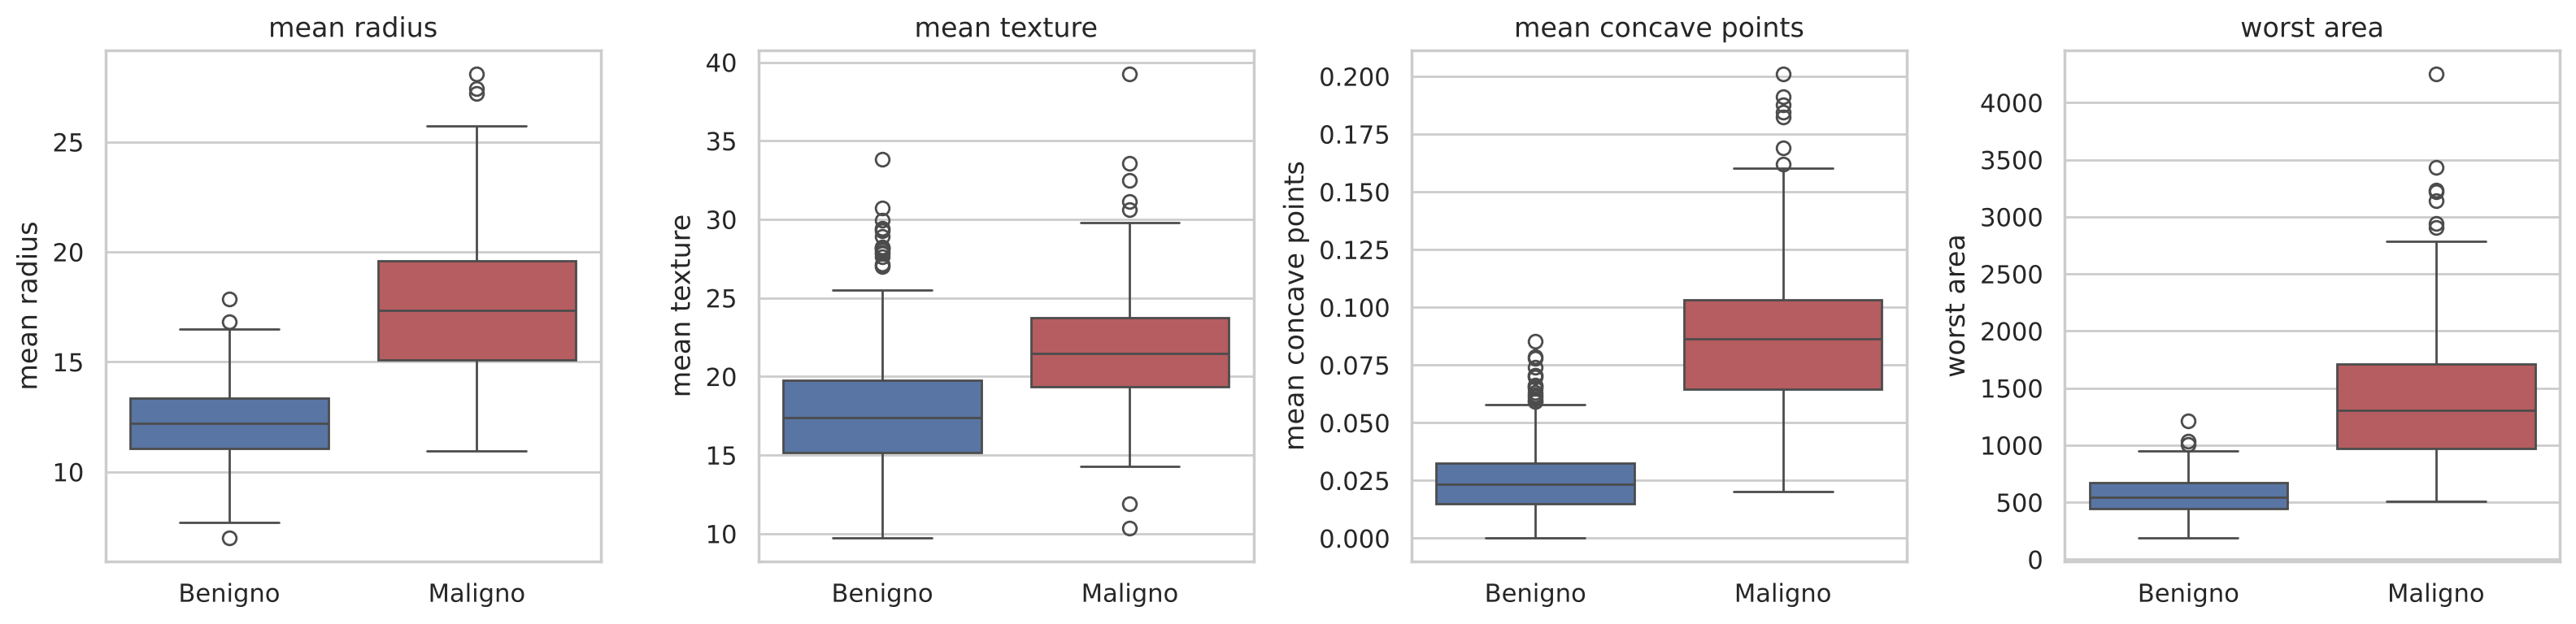

In [5]:
principais = ["mean radius", "mean texture", "mean concave points", "worst area"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, principais):
    sns.boxplot(data=df, x="diagnostico", y=col, ax=ax, hue="diagnostico",
                palette=["#4C72B0", "#C44E52"], legend=False)
    ax.set_xticks([0, 1], ["Benigno", "Maligno"]); ax.set_xlabel("")
    ax.set_title(col)
plt.tight_layout(); plt.show()

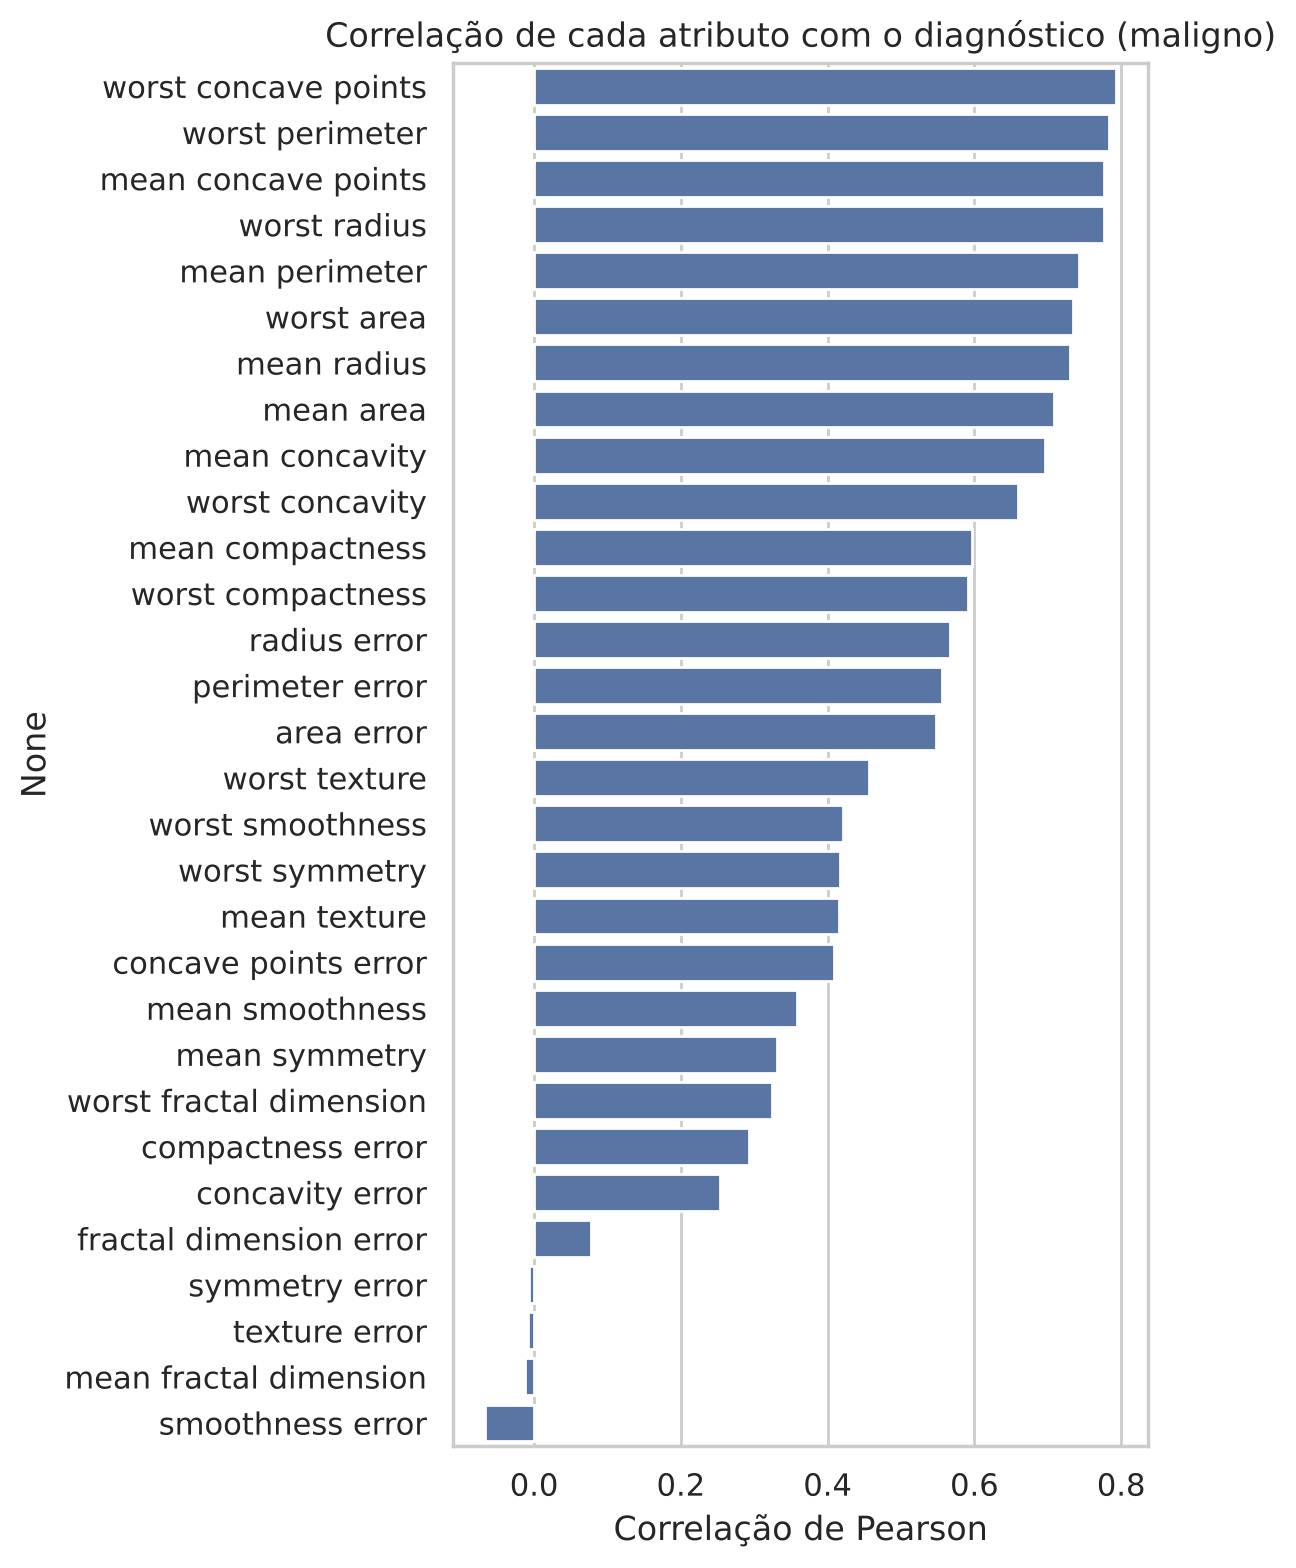

In [6]:
corr = df.corr()["diagnostico"].drop("diagnostico").sort_values(ascending=False)
plt.figure(figsize=(6, 8))
sns.barplot(x=corr.values, y=corr.index, color="#4C72B0")
plt.title("Correlação de cada atributo com o diagnóstico (maligno)")
plt.xlabel("Correlação de Pearson"); plt.tight_layout(); plt.show()

Atributos ligados a **tamanho** (raio, perímetro, área) e à **forma irregular** do núcleo (concavidade, pontos côncavos) são os mais associados a tumores malignos. Já dá para esperar que modelos simples tenham um bom desempenho.

## 2. Tipo de análise

- **Tipo de aprendizado:** supervisionado.
- **Tarefa:** **classificação binária**, que consiste em prever se um nódulo é maligno (1) ou benigno (0) a partir dos 30 atributos.
- **Abordagem:** comparar quatro algoritmos de famílias diferentes:
  - Regressão Logística (linear)
  - K-Nearest Neighbors (baseado em distância)
  - SVM com kernel RBF (baseado em margem)
  - Random Forest (ensemble de árvores)
- **Validação:** divisão 80% treino / 20% teste (estratificada) e validação cruzada estratificada de 5 folds no treino. O conjunto de teste só é usado no final.
- **Métricas:** acurácia, precisão, **recall (sensibilidade)**, F1 e ROC-AUC.
  No contexto médico, um **falso negativo** (dizer que um tumor maligno é benigno) é o erro mais grave. Por isso o **recall da classe maligna** é a métrica prioritária.

## 3. Implementação

In [7]:
X = df.drop(columns="diagnostico")
y = df["diagnostico"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras")

Treino: 455 amostras | Teste: 114 amostras


### 3.1 Comparação dos modelos com validação cruzada
Cada modelo fica dentro de um `Pipeline` junto com o `StandardScaler`. Assim a padronização é ajustada só com os dados de treino de cada fold, o que evita *data leakage*.

In [8]:
modelos = {
    "Regressão Logística": LogisticRegression(max_iter=5000, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(),
    "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metricas = ["accuracy", "precision", "recall", "f1", "roc_auc"]

resultados = []
for nome, modelo in modelos.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("modelo", modelo)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas)
    linha = {"Modelo": nome}
    for m in metricas:
        linha[m] = s[f"test_{m}"].mean()
    resultados.append(linha)

tabela_cv = pd.DataFrame(resultados).set_index("Modelo").sort_values("recall", ascending=False)
tabela_cv.round(4)

,accuracy,precision,recall,f1,roc_auc
Modelo,,,,,
Regressão Logística,0.9736,0.9771,0.9529,0.9640,0.9958
SVM (RBF),0.9714,0.9769,0.9471,0.9610,0.9949
Random Forest,0.9648,0.9641,0.9412,0.9519,0.9889
KNN,0.9648,0.9875,0.9176,0.9510,0.9871


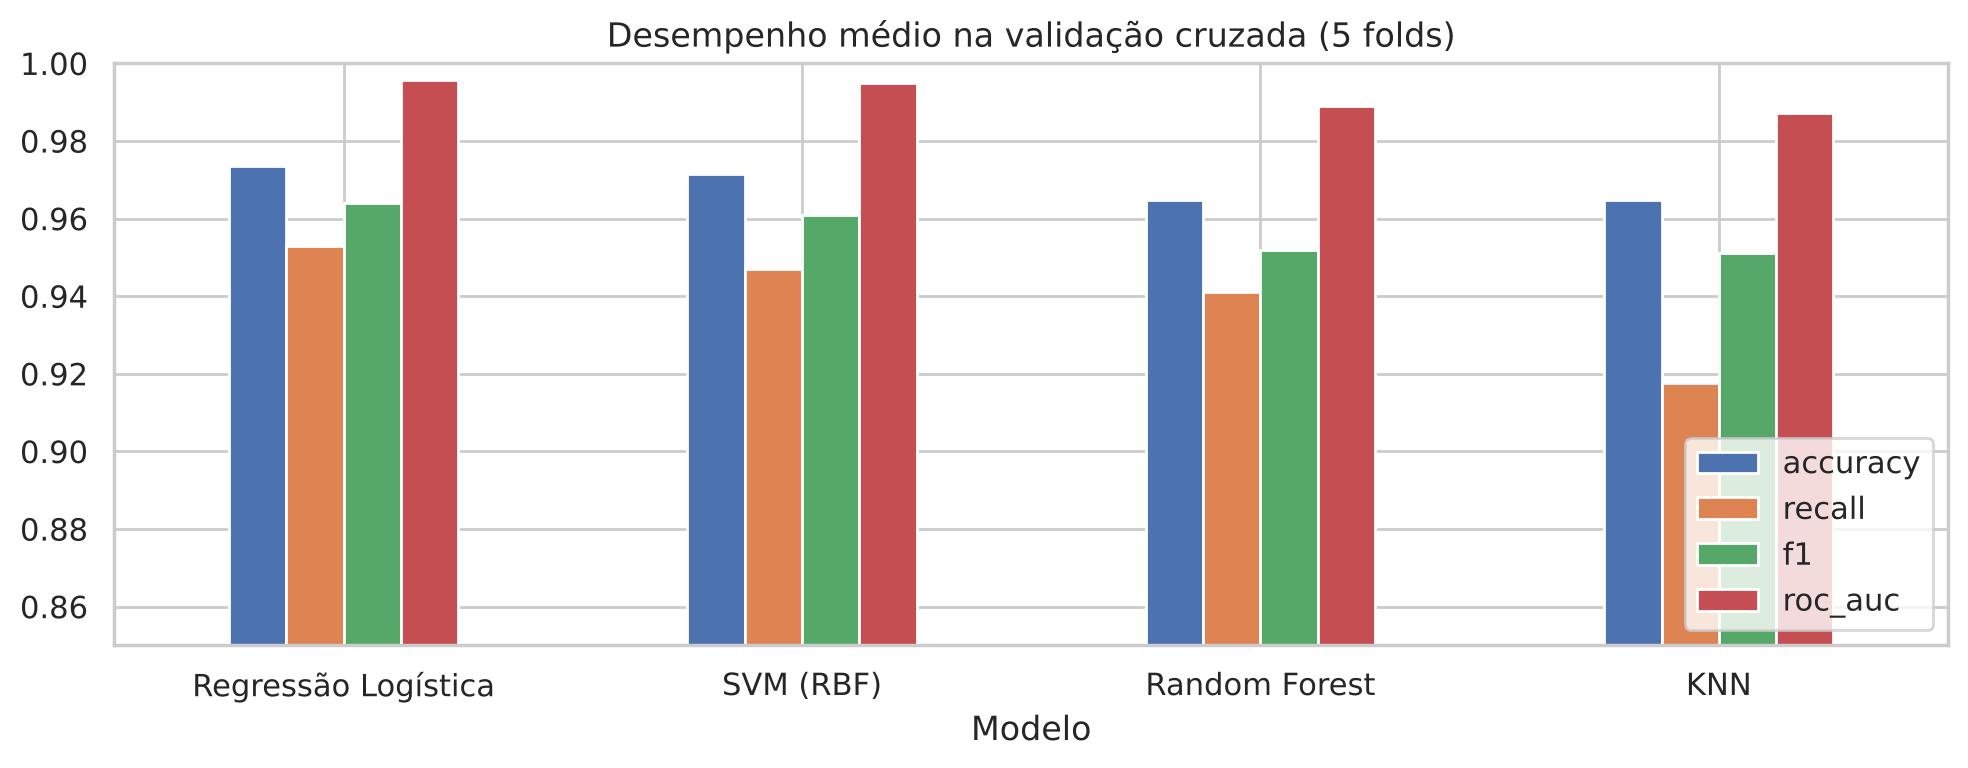

In [9]:
ax = tabela_cv[["accuracy", "recall", "f1", "roc_auc"]].plot(kind="bar", figsize=(10, 4), rot=0)
ax.set_ylim(0.85, 1.0); ax.set_title("Desempenho médio na validação cruzada (5 folds)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 3.2 Ajuste de hiperparâmetros do melhor modelo
Pegamos o modelo com melhor desempenho na validação cruzada e otimizamos seus hiperparâmetros com `GridSearchCV`, usando o **recall** como critério de escolha.

In [10]:
melhor_nome = tabela_cv["f1"].idxmax()
print("Modelo escolhido para ajuste:", melhor_nome)

grades = {
    "Regressão Logística": {"modelo__C": [0.01, 0.1, 1, 10, 100]},
    "KNN": {"modelo__n_neighbors": [3, 5, 7, 9, 11], "modelo__weights": ["uniform", "distance"]},
    "SVM (RBF)": {"modelo__C": [0.1, 1, 10, 100], "modelo__gamma": ["scale", 0.001, 0.01, 0.1]},
    "Random Forest": {"modelo__n_estimators": [100, 300], "modelo__max_depth": [None, 5, 10]},
}
pipe = Pipeline([("scaler", StandardScaler()), ("modelo", modelos[melhor_nome])])
busca = GridSearchCV(pipe, grades[melhor_nome], cv=cv, scoring="recall", n_jobs=-1)
busca.fit(X_train, y_train)

print("Melhores hiperparâmetros:", busca.best_params_)
print(f"Recall médio (CV): {busca.best_score_:.4f}")
modelo_final = busca.best_estimator_

Modelo escolhido para ajuste: Regressão Logística


Melhores hiperparâmetros: {'modelo__C': 1}
Recall médio (CV): 0.9529


### 3.3 Avaliação final no conjunto de teste

In [11]:
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"], digits=4))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")

              precision    recall  f1-score   support

     Benigno     0.9595    0.9861    0.9726        72
     Maligno     0.9750    0.9286    0.9512        42

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114

ROC-AUC: 0.9960


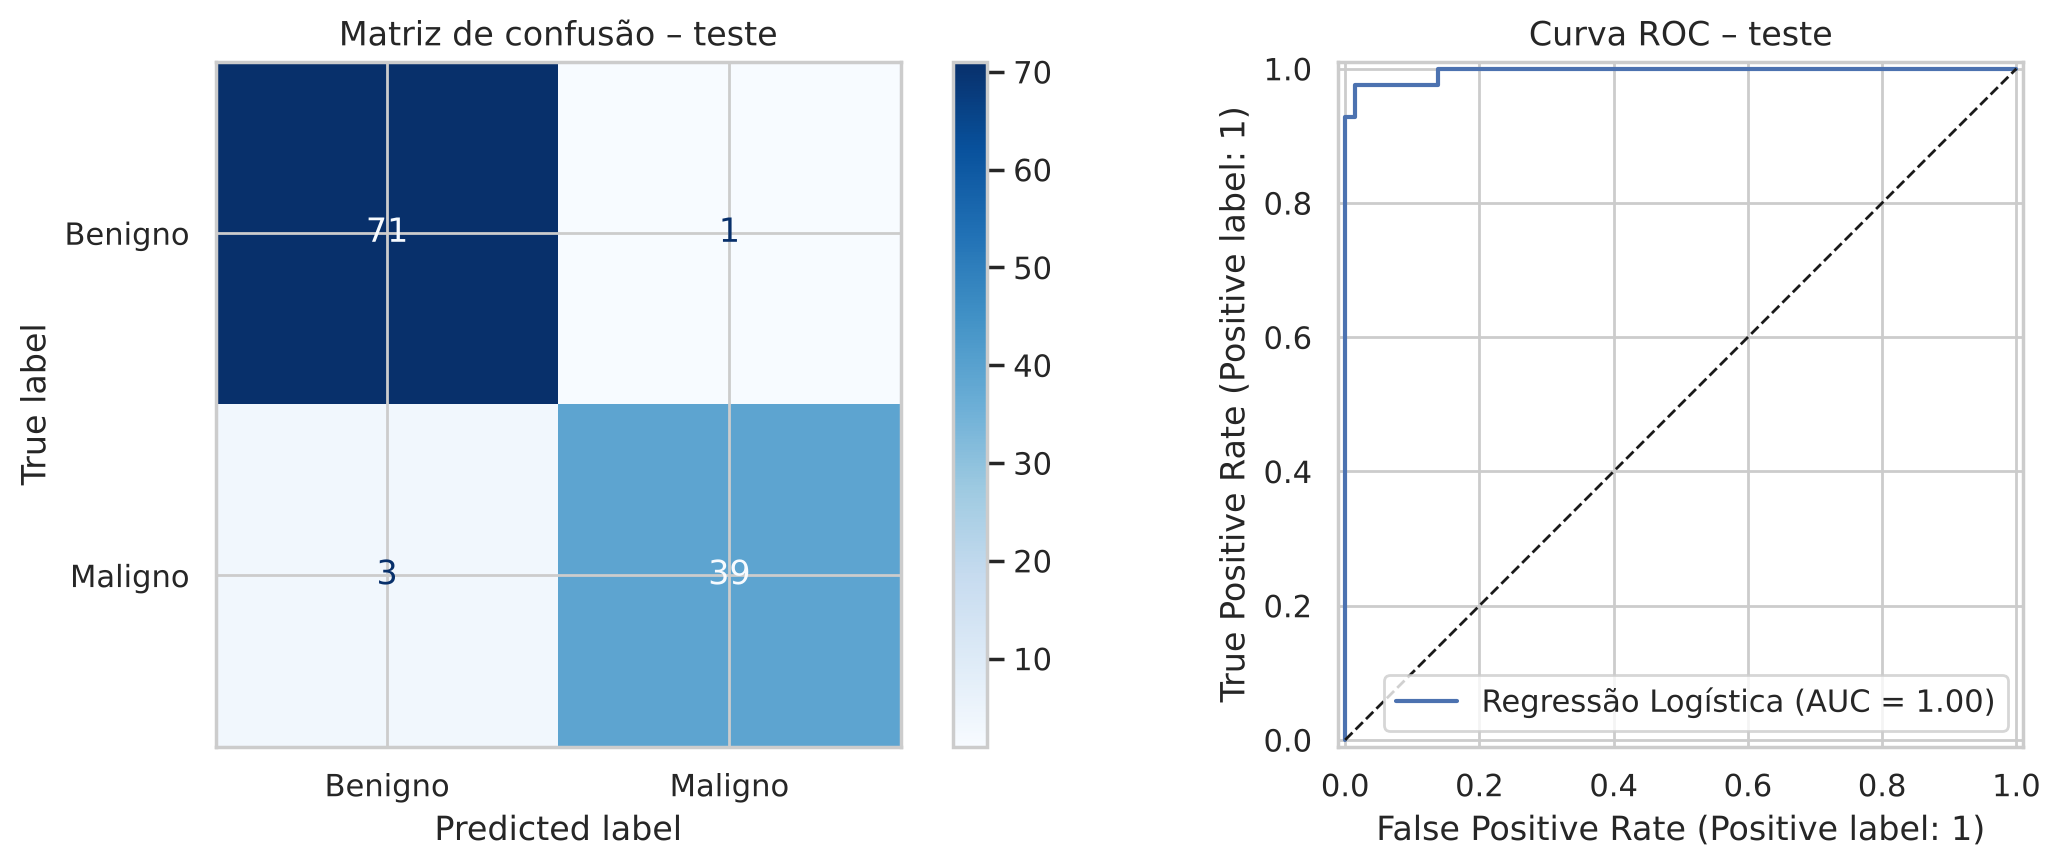

Verdadeiros positivos (malignos detectados): 39
Falsos negativos (malignos não detectados):  3
Falsos positivos (benignos alarmados):       1
Verdadeiros negativos:                       71


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Benigno", "Maligno"],
                                        cmap="Blues", ax=axes[0])
axes[0].set_title("Matriz de confusão – teste")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=melhor_nome)
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_title("Curva ROC – teste")
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f"Verdadeiros positivos (malignos detectados): {tp}")
print(f"Falsos negativos (malignos não detectados):  {fn}")
print(f"Falsos positivos (benignos alarmados):       {fp}")
print(f"Verdadeiros negativos:                       {tn}")

### 3.4 Interpretação: quais atributos mais pesam?
Para saber quais variáveis o modelo mais usa, treinamos uma Random Forest e olhamos a **importância dos atributos**. Ela serve como referência porque esse número se interpreta direto, seja qual for o modelo final.

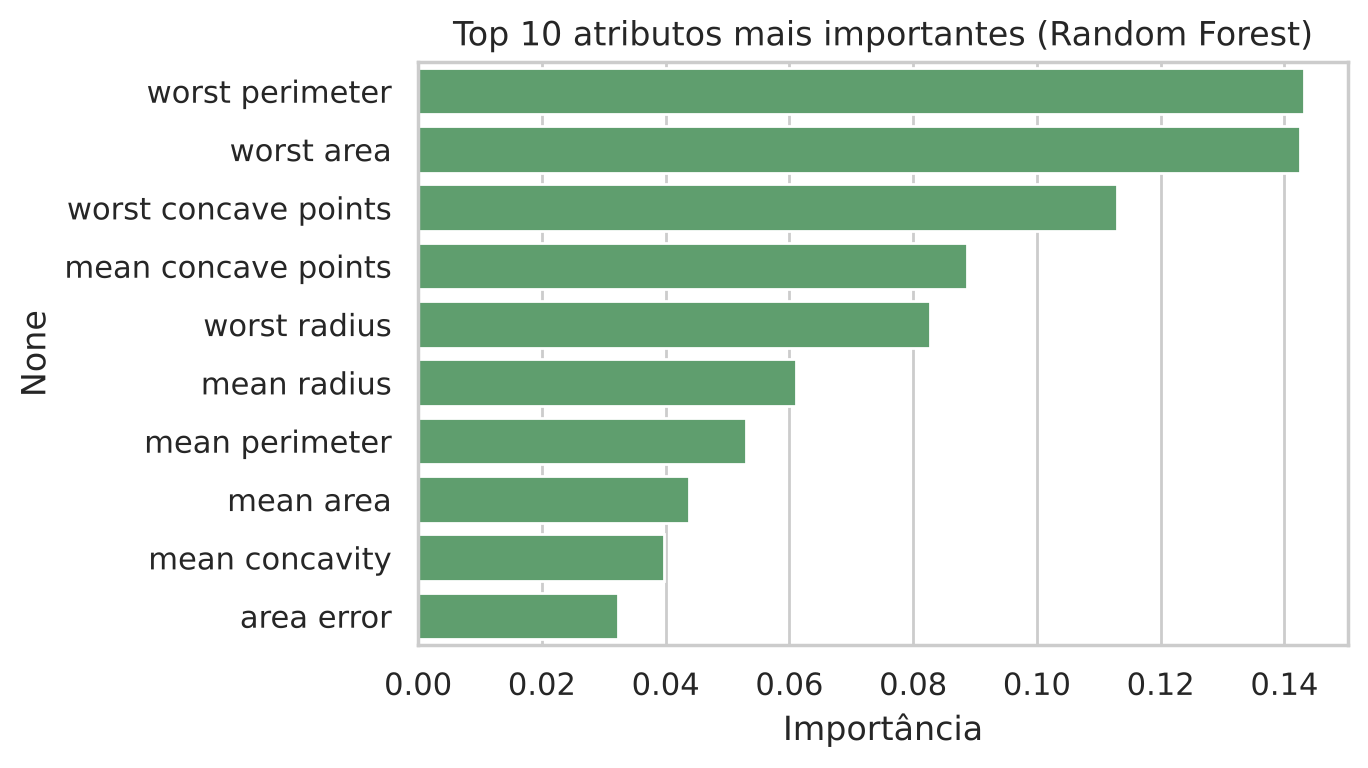

In [13]:
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_train, y_train)
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(7, 4))
sns.barplot(x=imp.values, y=imp.index, color="#55A868")
plt.title("Top 10 atributos mais importantes (Random Forest)"); plt.xlabel("Importância")
plt.tight_layout(); plt.show()

### 3.5 Bônus: ajuste do limiar de decisão
Por padrão, o classificador marca "maligno" quando a probabilidade passa de 0,5. Como um falso negativo é o erro mais caro, dá para **baixar o limiar** e trocar alguns falsos positivos por menos falsos negativos.

In [14]:
for limiar in [0.5, 0.4, 0.3, 0.2]:
    pred = (y_proba >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"Limiar {limiar:.1f} -> recall maligno = {recall_score(y_test, pred):.3f} | FN = {fn} | FP = {fp}")

Limiar 0.5 -> recall maligno = 0.929 | FN = 3 | FP = 1
Limiar 0.4 -> recall maligno = 0.952 | FN = 2 | FP = 1
Limiar 0.3 -> recall maligno = 0.976 | FN = 1 | FP = 1
Limiar 0.2 -> recall maligno = 0.976 | FN = 1 | FP = 4


## Conclusões

- A base Breast Cancer Wisconsin foi usada numa tarefa de **classificação binária supervisionada**, com quatro algoritmos comparados por validação cruzada estratificada de 5 folds.
- Todos os modelos passaram de **96% de acurácia** na validação cruzada. A **Regressão Logística** foi a melhor (acurácia 97,4%, F1 0,964, ROC-AUC 0,996), seguida de perto pelo SVM. Isso mostra que as classes são quase linearmente separáveis.
- Depois do ajuste de hiperparâmetros (melhor `C = 1`), o modelo chegou a **96,5% de acurácia** e **ROC-AUC de 0,996** no conjunto de teste, que não foi usado durante o treino. São valores próximos aos da validação cruzada, o que indica que **não houve overfitting**.
- No teste, o modelo detectou **39 dos 42 tumores malignos** (recall 92,9%) e gerou só 1 falso positivo.
- Baixando o **limiar de decisão** de 0,5 para 0,3, o recall da classe maligna subiu para **97,6%** (1 falso negativo) sem aumentar os falsos positivos. Essa configuração é mais adequada para uma ferramenta de **apoio** ao diagnóstico, em que a decisão final continua sendo do especialista.
- Os atributos mais relevantes são ligados a **tamanho** e **irregularidade** do núcleo (pontos côncavos, área, raio e perímetro no "pior" valor), o que bate com a análise exploratória.

**Limitações e trabalhos futuros:** a base é pequena (569 amostras) e vem de uma única instituição, e o limiar foi escolhido olhando o próprio conjunto de teste. O ideal seria definir o limiar num conjunto de validação separado e testar o modelo com dados externos. Também dá para aplicar PCA ou seleção de atributos para reduzir a redundância entre variáveis muito correlacionadas, e usar técnicas de explicabilidade como o SHAP.